# T34. Curva de flota frente a nivel de servicio e indicadores de uso

**Objetivo.** Medir cuántos viajes se atienden y cuánto se usa cada patinete según el tamaño de la flota, con la red elegida en T28 (`lscp_r300_k159`) y los 966 anclajes que dimensiona T32.

**Valor.** El enunciado pide a la vez minimizar el número de patinetes y maximizar su uso. Esta curva pone en una misma figura lo que se gana y lo que se pierde con cada patinete más, y fija el tamaño de la flota con un criterio decidido antes de ver el resultado.

**Método.** Se mantiene la red y los anclajes de cada estación. La flota se reparte entre estaciones en proporción al stock de diseño de T32, sin pasar de los anclajes de cada una, y se barre de 150 a 900 patinetes de 25 en 25. Cada tamaño se simula con el simulador de T32 (`inventario.py`, mismas reglas) con 0, 100 y 220 recolocaciones por noche. **Criterio:** la menor flota que atiende al menos el 95 % de los viajes cubiertos con el rebalanceo base de 100, el mismo objetivo que usa T32.

## 1. Servicio según el tamaño de la flota

**Qué queremos ver.** El porcentaje de viajes cubiertos que se atienden para cada tamaño de flota y cada límite de rebalanceo, y cuántos se rechazan por falta de patinete o de anclaje.

**Por qué importa.** Con pocos patinetes faltan vehículos; con muchos, las estaciones se llenan y no hay dónde dejarlos. La flota buena está entre los dos extremos y depende de los anclajes que haya.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import display

from comun.config import cargar_config
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar
from inventario import Demanda, Red, repartir_flota, simular
from redes import guardar, leer

cfg = cargar_config()["movilidad"]
REBALANCEO_BASE = cfg["rebalanceo_base_patinetes_dia"]
REBALANCEOS = cfg["rebalanceo_sensibilidad_patinetes_dia"]
SERVICIO_OBJETIVO = 95   # el mismo criterio que T32
FLOTAS = list(range(150, 901, 25))

catalogo = leer("T32_estaciones")
red_id = catalogo["network_id"].iloc[0]
radio = float(leer("T28_finalistas").query("network_id == @red_id")["radio_m"].iloc[0])
red = Red.de_tabla(catalogo, radio)
anclajes = catalogo["anclajes"].to_numpy(int)
stock_diseno = catalogo["stock_diseno"].to_numpy(int)
dem = Demanda.de_viajes(cargar_viajes(periodo="ajuste"), red)


def stock_para(flota):
    """Reparte la flota en proporción al stock de diseño de T32 sin pasar de los anclajes de cada estación."""
    return repartir_flota(stock_diseno, anclajes, flota)


assert stock_para(int(stock_diseno.sum())).tolist() == stock_diseno.tolist()

filas = []
for reb in REBALANCEOS:
    for flota in FLOTAS:
        r = simular(dem, red, stock_para(flota), anclajes, reb)
        e = r.estaciones
        filas.append({**{k: v for k, v in r.resumen.items() if k != "desvio"},
                      "mediana_pct_tiempo_vacia": e["pct_tiempo_vacia"].median(),
                      "mediana_pct_tiempo_llena": e["pct_tiempo_llena"].median()})
curva = pd.DataFrame(filas)
guardar(curva, "T34_curva_flota")

base = curva.loc[curva["rebalanceo_max"].eq(REBALANCEO_BASE)].reset_index(drop=True)
cumple = base.loc[base["pct_atendidos_cubiertos"].ge(SERVICIO_OBJETIVO)]
flota_min = int(cumple["flota"].min()) if len(cumple) else None
mejor = base.loc[base["pct_atendidos_cubiertos"].idxmax()]
# T32 usa esta flota para el catálogo, la asignación (T31) y el consumo: tiene que seguir siendo la mínima.
if flota_min != int(catalogo["stock_inicial"].sum()):
    raise ValueError(f"La flota mínima es {flota_min}: cambia FLOTA en T32 y vuelve a ejecutar T32 y T31.")
print(f"Flota mínima para el {SERVICIO_OBJETIVO} % con {REBALANCEO_BASE} recolocaciones: {flota_min}")
print(f"Máximo servicio: {mejor['pct_atendidos_cubiertos']:.2f} % con {int(mejor['flota'])} patinetes")
display(base[["flota", "pct_atendidos_cubiertos", "n_sin_patinete", "n_sin_anclaje", "viajes_por_patinete_dia",
              "pct_tiempo_en_viaje", "mediana_pct_tiempo_vacia", "mediana_pct_tiempo_llena"]].round(2))

Flota mínima para el 95 % con 100 recolocaciones: 400
Máximo servicio: 95.92 % con 475 patinetes


,flota,pct_atendidos_cubiertos,n_sin_patinete,n_sin_anclaje,viajes_por_patinete_dia,pct_tiempo_en_viaje,mediana_pct_tiempo_vacia,mediana_pct_tiempo_llena
0,150,74.32,3433,11,3.16,2.40,32.37,0.00
1,175,78.81,2824,18,2.87,2.19,27.56,0.00
2,200,82.49,2324,24,2.63,2.02,24.10,0.00
3,225,85.47,1902,46,2.42,1.86,20.30,0.00
4,250,87.54,1631,40,2.23,1.71,18.45,0.00
5,275,89.98,1279,65,2.09,1.60,15.02,0.17
6,300,91.54,1061,74,1.95,1.50,13.49,0.41
7,325,92.80,873,92,1.82,1.41,12.06,0.60
8,350,93.80,722,110,1.71,1.32,9.30,1.10
9,375,94.48,592,148,1.61,1.24,7.94,1.60


**Conclusiones.**
- **400 patinetes son la flota más pequeña que llega al 95 %** con 100 recolocaciones por noche (95,1 %). Son 74 menos que el diseño de T32 (474). Con 375 se queda en el 94,5 %. El barrido va de 25 en 25, así que el mínimo exacto está entre 376 y 400.
- **El servicio tiene un máximo:** el 95,9 % con 475 patinetes, prácticamente el diseño de T32. A partir de ahí, más patinetes empeoran el servicio: con 600 se atiende el 93,3 % y con 700, el 87,7 %. Con los anclajes fijos, las estaciones se llenan y los rechazos por falta de anclaje pasan de 187 (400 patinetes) a 809 (600) y 1 632 (700).
- **El rebalanceo vale unos 10 puntos.** Sin él, el máximo es el 85,7 % (525 patinetes). Con 220 recolocaciones en vez de 100, el máximo solo sube al 96,6 % y con 400 patinetes se llega al 95,4 %: con estos anclajes, lo que limita es la capacidad de las estaciones.

## 2. Uso de los patinetes frente a servicio

**Qué queremos ver.** Junto al servicio, los viajes por patinete y día y el porcentaje del tiempo que cada patinete pasa en viaje.

**Por qué importa.** Es el segundo objetivo del enunciado: maximizar el uso de los patinetes. Cada patinete de más baja el uso medio, y solo compensa si sube el servicio.

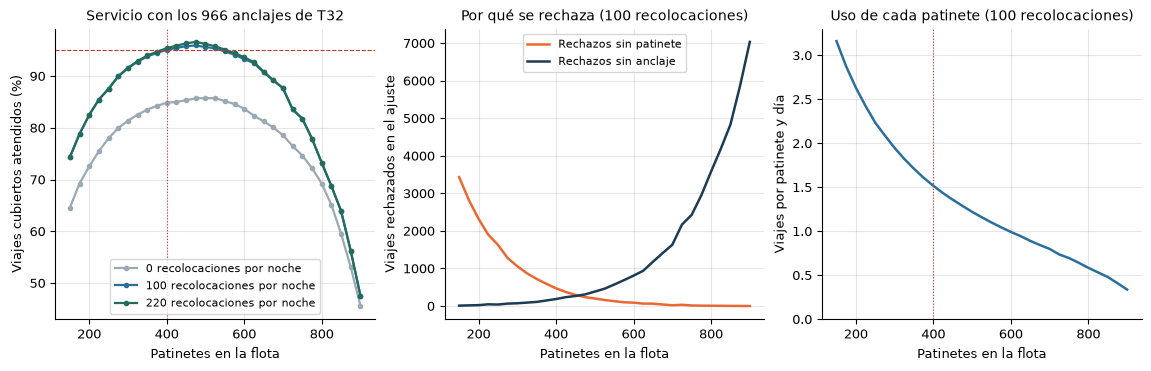

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(11.4, 3.6), layout="constrained")
colores = {0: "#9aa9b3", 100: "#2a6f9b", 220: "#226c5b"}
ax = axes[0]
for reb, g in curva.groupby("rebalanceo_max"):
    ax.plot(g["flota"], g["pct_atendidos_cubiertos"], marker="o", ms=3, lw=1.6, color=colores.get(reb, "#444"),
            label=f"{reb} recolocaciones por noche")
ax.axhline(SERVICIO_OBJETIVO, color="#c0392b", lw=.8, ls="--")
if flota_min:
    ax.axvline(flota_min, color="#c0392b", lw=.8, ls=":")
ax.set(xlabel="Patinetes en la flota", ylabel="Viajes cubiertos atendidos (%)",
       title=f"Servicio con los {int(anclajes.sum())} anclajes de T32")
ax.legend(fontsize=8, loc="lower center")
ax = axes[1]
ax.plot(base["flota"], base["n_sin_patinete"], color="#eb6834", lw=1.8, label="Rechazos sin patinete")
ax.plot(base["flota"], base["n_sin_anclaje"], color="#1d3b53", lw=1.8, label="Rechazos sin anclaje")
ax.set(xlabel="Patinetes en la flota", ylabel="Viajes rechazados en el ajuste",
       title=f"Por qué se rechaza ({REBALANCEO_BASE} recolocaciones)")
ax.legend(fontsize=8, loc="upper center")
ax = axes[2]
ax.plot(base["flota"], base["viajes_por_patinete_dia"], color="#2a6f9b", lw=1.8)
if flota_min:
    ax.axvline(flota_min, color="#c0392b", lw=.8, ls=":")
ax.set(xlabel="Patinetes en la flota", ylabel="Viajes por patinete y día",
       title=f"Uso de cada patinete ({REBALANCEO_BASE} recolocaciones)", ylim=(0, None))
guardar_figura(fig, "movilidad", "T34_curva_flota")
plt.show()

**Conclusiones.**
- **Pasar de 400 a 475 patinetes da 0,8 puntos de servicio** (del 95,1 % al 95,9 %) a cambio de un 19 % más de flota. El uso baja de 1,52 a 1,29 viajes por patinete y día, y el tiempo en viaje, del 1,17 % al 0,99 %.
- Por debajo de 400, cada patinete rinde más, pero el servicio cae deprisa: con 300 se atiende el 91,5 %.
- Los patinetes pasan menos del 2 % del tiempo en viaje en cualquier flota razonable. El tamaño lo decide dónde y cuándo hacen falta, no cuántos viajes hay a la vez (como mucho 41 a la vez en el ajuste, T12).
- Como referencia, Helbiz usó de media 487,8 patinetes distintos al día (T12), pero para todos sus viajes. Esta red cubre el 80 % y lo hace con 400.

## 3. La flota elegida en la semana reservada

**Qué queremos ver.** El diseño de T32 (474 patinetes) y la flota mínima (400) simulados con los viajes del 22 al 28 de febrero, con las mismas estaciones y anclajes.

**Por qué importa.** La semana reservada tiene un 18 % más de demanda diaria. Dice cuánto margen se pierde al recortar la flota.

In [3]:
dem_res = Demanda.de_viajes(cargar_viajes(periodo="reservada"), red)
elegida = flota_min or int(mejor["flota"])
comparacion = []
for nombre, flota in (("diseño T32", int(stock_diseno.sum())), ("mínima para el objetivo", elegida)):
    for periodo, d in (("ajuste", dem), ("reservada", dem_res)):
        r = simular(d, red, stock_para(flota), anclajes, REBALANCEO_BASE).resumen
        comparacion.append({"caso": nombre, "periodo": periodo, **{k: v for k, v in r.items() if k != "desvio"}})
comparacion = pd.DataFrame(comparacion)
guardar(comparacion, "T34_comparacion")
display(comparacion[["caso", "periodo", "flota", "pct_atendidos_cubiertos", "pct_atendidos_total",
                     "viajes_por_patinete_dia", "pct_tiempo_en_viaje"]].round(2))

exportar("fase1", "t34_flota", {
    "network_id": red_id, "radio_m": radio, "anclajes": int(anclajes.sum()), "flota_diseno": int(stock_diseno.sum()),
    "servicio_objetivo": SERVICIO_OBJETIVO, "rebalanceo_base": REBALANCEO_BASE, "flota_minima": flota_min,
    "curva": curva, "comparacion": comparacion,
})

,caso,periodo,flota,pct_atendidos_cubiertos,pct_atendidos_total,viajes_por_patinete_dia,pct_tiempo_en_viaje
0,diseño T32,ajuste,474,95.94,76.78,1.29,1.00
1,diseño T32,reservada,474,94.18,71.21,1.42,1.14
2,mínima para el objetivo,ajuste,400,95.09,76.09,1.52,1.17
3,mínima para el objetivo,reservada,400,93.38,70.61,1.67,1.34


**Conclusiones.**
- Con 400 patinetes, en la semana reservada se atiende el 93,4 % de los viajes cubiertos, frente al 94,2 % con 474. Ninguna de las dos llega al 95 % fuera de la muestra, y la diferencia (0,8 puntos) es parecida a la del ajuste (0,9).
- Con 400 patinetes se rechazan 259 viajes por falta de patinete (177 con 474), pero menos por falta de anclaje (72 frente a 114).
- **Decisión:** 400 patinetes y los 966 anclajes de T32, porque es lo que da el criterio fijado y el enunciado pide la flota más pequeña con el mayor uso. El diseño de 474 queda como alternativa con más margen si crece la demanda. T32 reparte los 400 entre estaciones, y esa simulación es la que usan la asignación (T31) y el consumo.

## Decisiones

| Decisión | Valor propuesto | Evidencia | Periodo | Limitaciones | Qué cambia en el plan |
|---|---|---|---|---|---|
| Tamaño de la flota | **400 patinetes** (95,1 % de los viajes cubiertos con 100 recolocaciones por noche) | `T34_curva_flota.csv`, figura `T34_curva_flota` | Ajuste | Barrido de 25 en 25; reparto proporcional al stock de diseño de T32 | El catálogo de T32 lleva el stock de estos 400; T31 y el consumo usan su simulación |
| Alternativa | 474 patinetes (diseño de T32): 95,9 %, máximo de la curva | `T34_curva_flota.csv` | Ajuste | — | Más margen ante crecimiento de la demanda |
| Relación entre patinetes y anclajes | 2,4 anclajes por patinete con la flota elegida. Más flota sin más anclajes empeora el servicio a partir de unos 475 patinetes | `T34_curva_flota.csv` | Ajuste | Anclajes fijos en el diseño P90 de T32 | Flota y anclajes se dimensionan juntos |
| Validación | 93,4 % con 400 patinetes y 94,2 % con 474 en la semana reservada | `T34_comparacion.csv` | Reservada | Una sola semana, con un 18 % más de demanda | Margen a tener en cuenta si la demanda crece |